# NN_L10_spread_monthly

**Monthly mean of the daily max-min spread of day-ahead prices in Romania and Germany-Luxembourg, the income source of a battery.**

Neural Networks and Deep Learning (NN), Lecture 10 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L10/NN_L10_spread_monthly/NN_L10_spread_monthly.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Daily spread = max - min of the 24 hourly day-ahead prices of a delivery day (CET), days with 24 complete hours.

mean daily spread RO 2019 (EUR/MWh) = 47.9   [spread.ro_2019]
mean daily spread RO 2025 (EUR/MWh) = 164.3   [spread.ro_2025]
mean daily spread RO 2026 YTD (EUR/MWh) = 182.8   [spread.ro_ytd]


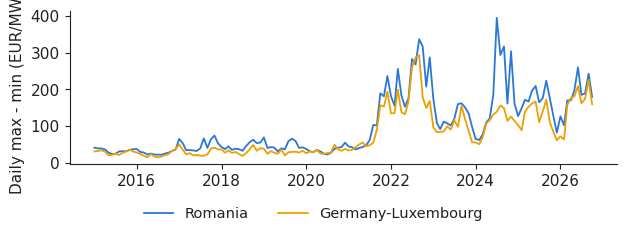

In [3]:
import torch, torch.nn as nn
x = pd.read_csv(DATA + 'power_da_prices_hourly_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
x.index = x.index.tz_convert('Europe/Brussels')
END = '2026-10-31'                                   # last complete month of the course data
x = x.loc[:END + ' 23:59']
x['day'] = x.index.tz_localize(None).normalize(); x['hour'] = x.index.hour
def day_matrix(zone):
    d = x[['day', 'hour', zone]].dropna(); n = d.groupby('day')[zone].count()
    return d[d.day.isin(n[n == 24].index)].pivot_table(index='day', columns='hour', values=zone).sort_index()
RO = day_matrix('RO')
DE = day_matrix('DE_LU')
sp = RO.max(axis=1) - RO.min(axis=1)
y = sp.groupby(sp.index.year).mean()
show('spread.ro_2019', 'mean daily spread RO 2019 (EUR/MWh)', round(float(y.loc[2019]), 1))
show('spread.ro_2025', 'mean daily spread RO 2025 (EUR/MWh)', round(float(y.loc[2025]), 1))
show('spread.ro_ytd', 'mean daily spread RO 2026 YTD (EUR/MWh)', round(float(y.loc[2026]), 1))
fig, ax = plt.subplots(figsize=(6.4, 2.4))
for M, c, lab in ((RO, PAL['data'], 'Romania'), (DE, PAL['alt'], 'Germany-Luxembourg')):
    s_ = (M.max(axis=1) - M.min(axis=1)).resample('MS').mean(); ax.plot(s_.index, s_.values, color=c, lw=1.3, label=lab)
ax.set_ylabel('Daily max - min (EUR/MWh)'); legend_bottom(fig); fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig('spread_monthly.png', dpi=200, transparent=True, bbox_inches='tight'); plt.show()